In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("data/raw/india_ev_range_dataset.csv")
print("All files loaded successfully!")


All files loaded successfully!


In [3]:
df.head()

,make,model,variant,battery_capacity_kWh,battery_capacity_kWh_new,motor_power_kW,vehicle_weight_kg,drag_coefficient_Cd,frontal_area_m2,rolling_resistance_Cr,...,terrain_type,traffic_condition,driving_style,passengers,battery_age_years,tyre_pressure_deviation_psi,city_road_type,energy_consumption_kWh_per_km,real_world_range_km,price_lakh_INR
0,Tata,Nexon EV,Long Range,35.3,40.5,105,1610,0.34,2.4,0.0122,...,0,2,0,1,4.3,-2,Delhi,0.2504,141.00,17.5
1,Tata,Nexon EV,Long Range,40.5,40.5,105,1610,0.34,2.4,0.0120,...,0,2,1,3,0.0,0,Delhi,0.1198,338.00,17.5
2,Tata,Nexon EV,Long Range,39.3,40.5,105,1610,0.34,2.4,0.0122,...,0,1,1,3,1.0,-2,Delhi,0.1254,313.40,17.5
3,Tata,Nexon EV,Long Range,39.0,40.5,105,1610,0.34,2.4,0.0120,...,0,0,1,1,1.2,0,Delhi,0.0883,441.75,17.5
4,Tata,Nexon EV,Long Range,37.9,40.5,105,1610,0.34,2.4,0.0120,...,0,2,0,3,2.1,0,Delhi,0.1960,193.40,17.5


In [4]:
df.shape

(7291, 25)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7291 entries, 0 to 7290
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   make                           7291 non-null   object 
 1   model                          7291 non-null   object 
 2   variant                        7291 non-null   object 
 3   battery_capacity_kWh           7291 non-null   float64
 4   battery_capacity_kWh_new       7291 non-null   float64
 5   motor_power_kW                 7291 non-null   int64  
 6   vehicle_weight_kg              7291 non-null   int64  
 7   drag_coefficient_Cd            7291 non-null   float64
 8   frontal_area_m2                7291 non-null   float64
 9   rolling_resistance_Cr          7291 non-null   float64
 10  motor_efficiency_pct           7291 non-null   int64  
 11  ARAI_certified_range_km        7291 non-null   int64  
 12  avg_driving_speed_kmh          7291 non-null   f

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_capacity_kWh,7291.0,57.063503,21.639038,14.7000,39.800,57.5000,71.50000,107.8000
battery_capacity_kWh_new,7291.0,61.730462,23.235641,17.3000,44.500,61.0000,77.40000,107.8000
motor_power_kW,7291.0,192.297764,114.756511,30.0000,110.000,160.0000,250.00000,560.0000
vehicle_weight_kg,7291.0,1915.502263,459.599245,840.0000,1620.000,1900.0000,2170.00000,2975.0000
drag_coefficient_Cd,7291.0,0.291849,0.037737,0.2000,0.280,0.2900,0.32000,0.3500
frontal_area_m2,7291.0,2.414042,0.176069,1.8000,2.330,2.4000,2.48000,2.8500
rolling_resistance_Cr,7291.0,0.011578,0.000964,0.0090,0.011,0.0116,0.01220,0.0140
motor_efficiency_pct,7291.0,92.048553,1.532851,88.0000,91.000,92.0000,93.00000,95.0000
ARAI_certified_range_km,7291.0,482.534220,115.686303,230.0000,418.000,476.0000,542.00000,857.0000
avg_driving_speed_kmh,7291.0,38.112317,26.438745,12.0000,21.500,28.0000,37.60000,120.0000


In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['make', 'model', 'variant', 'battery_capacity_kWh',
       'battery_capacity_kWh_new', 'motor_power_kW', 'vehicle_weight_kg',
       'drag_coefficient_Cd', 'frontal_area_m2', 'rolling_resistance_Cr',
       'motor_efficiency_pct', 'ARAI_certified_range_km',
       'avg_driving_speed_kmh', 'ambient_temperature_C', 'ac_usage',
       'terrain_type', 'traffic_condition', 'driving_style', 'passengers',
       'battery_age_years', 'tyre_pressure_deviation_psi', 'city_road_type',
       'energy_consumption_kWh_per_km', 'real_world_range_km',
       'price_lakh_INR'],
      dtype='object')

In [10]:
# Check target distribution
df["real_world_range_km"].describe()

count    7291.000000
mean      236.426800
std       145.732568
min        23.000000
25%       111.900000
50%       212.600000
75%       335.500000
max       814.150000
Name: real_world_range_km, dtype: float64

In [11]:
df['make'].value_counts()

make
Tata             1435
BYD               709
MG                609
Mahindra          601
BMW               590
Mercedes          486
Hyundai           482
Kia               361
Audi              356
Volvo             355
Citroen           251
Porsche           234
Maruti Suzuki     233
Smart             125
Jaguar            120
Mini              119
Rolls-Royce       114
Toyota            111
Name: count, dtype: int64

In [12]:
df['model'].value_counts()

model
Nexon EV            362
Curvv EV            251
eC3                 251
Ioniq 5             247
XUV400              239
ZS EV               236
XC40 Recharge       236
Tiago EV            236
Seal                235
Punch EV            235
Creta EV            235
Taycan              234
EV6                 234
e Vitara            233
Atto 3              232
EQA                 129
Cloud EV            129
Comet EV            128
EV9                 127
e6                  125
#1 Pro+             125
Q8 e-tron           124
EQS                 123
Harrier EV          122
BE 6                121
iX1                 121
XUV.e8              121
XEV 9e              120
I-PACE              120
C40 Recharge        119
e-tron              119
EQS SUV             119
i7                  119
Countryman E        119
i5                  118
i4                  118
Tigor EV            117
eMAX 7              117
Windsor EV          116
EQB                 115
Spectre             114
iX        

In [13]:
df['variant'].value_counts()

variant
Long Range        1668
Medium Range       594
Long Range AWD     373
Standard           367
55 quattro         243
580 4MATIC         242
eDrive40           236
Single Motor       236
Long Range RWD     235
EL Pro             129
250+               129
Shine              127
Exclusive          126
GL                 125
Feel               124
Smart              124
xDrive30           121
Extended Range     121
4S                 120
EV400              120
Twin Motor         119
ALL4               119
xDrive60           119
Performance        118
Prime LR           118
Dynamic            117
Ziptron            117
Premium            117
350 4MATIC         115
xDrive50           114
Turbo S            114
RS                 113
Standard Range     111
Excite             110
EC Pro             110
Name: count, dtype: int64

In [14]:
df['city_road_type'].value_counts()

city_road_type
Expressway      623
Mumbai          618
Ghat_Road       617
Delhi           616
Highway_NH      614
Chennai         612
Kolkata         606
Hill_Station    605
Pune            597
Hyderabad       597
Rural_Road      595
Bangalore       591
Name: count, dtype: int64

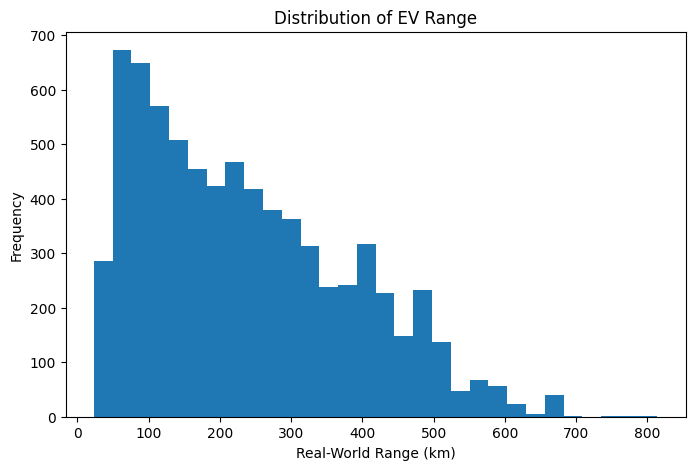

In [15]:
import matplotlib.pyplot as plt

# Target variable distribution
plt.figure(figsize=(8, 5))
plt.hist(df["real_world_range_km"], bins=30)
plt.xlabel("Real-World Range (km)")
plt.ylabel("Frequency")
plt.title("Distribution of EV Range")
plt.show()

In [16]:

# Step 3: Select 11 input features

features = [
    "make",
    "model",
    "variant",
    "battery_capacity_kWh",
    "motor_power_kW",
    "vehicle_weight_kg",
    "motor_efficiency_pct",
    "avg_driving_speed_kmh",
    "ambient_temperature_C",
    "city_road_type",
    "battery_age_years"
]

# Target variable
target = "real_world_range_km"

# Check whether all required columns exist
required_columns = features + [target]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Missing columns:", missing_columns)
else:
    print("All required columns are available!")

# Create feature data and target data
X = df[features].copy()
y = df[target].copy()

print("\nNumber of input features:", len(features))
print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())


All required columns are available!

Number of input features: 11
X shape: (7291, 11)
y shape: (7291,)


,make,model,variant,battery_capacity_kWh,motor_power_kW,vehicle_weight_kg,motor_efficiency_pct,avg_driving_speed_kmh,ambient_temperature_C,city_road_type,battery_age_years
0,Tata,Nexon EV,Long Range,35.3,105,1610,91,27.0,45.2,Delhi,4.3
1,Tata,Nexon EV,Long Range,40.5,105,1610,91,15.0,36.7,Delhi,0.0
2,Tata,Nexon EV,Long Range,39.3,105,1610,91,20.8,32.6,Delhi,1.0
3,Tata,Nexon EV,Long Range,39.0,105,1610,91,33.8,26.7,Delhi,1.2
4,Tata,Nexon EV,Long Range,37.9,105,1610,91,18.5,32.6,Delhi,2.1


In [17]:

# Step 4: Separate numerical and categorical features

numeric_features = [
    "battery_capacity_kWh",
    "motor_power_kW",
    "vehicle_weight_kg",
    "motor_efficiency_pct",
    "avg_driving_speed_kmh",
    "ambient_temperature_C",
    "battery_age_years"
]

categorical_features = [
    "make",
    "model",
    "variant",
    "city_road_type"
]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))


Numerical features: 7
Categorical features: 4
Total features: 11


# OneHotEncoder

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = X.select_dtypes(include="object").columns.tolist()
numerical_cols = X.select_dtypes(exclude="object").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape)
print("Testing rows:", X_test.shape)


print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training rows: (5832, 11)
Testing rows: (1459, 11)
Training target: (5832,)
Testing target: (1459,)


In [19]:

# Apply One-Hot Encoding to training data

X_train_encoded = preprocessor.fit_transform(X_train)

# Apply the same encoding to testing data
X_test_encoded = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Encoded training shape:", X_train_encoded.shape)

print("Original testing shape:", X_test.shape)
print("Encoded testing shape:", X_test_encoded.shape)

print("One-Hot Encoding completed successfully!")


Original training shape: (5832, 11)
Encoded training shape: (5832, 117)
Original testing shape: (1459, 11)
Encoded testing shape: (1459, 117)
One-Hot Encoding completed successfully!


In [20]:

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_encoded, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [21]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict on encoded test data
y_pred = model.predict(X_test_encoded)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} km")
print(f"RMSE: {rmse:.2f} km")
print(f"R2 Score: {r2:.4f}")
print(f"R2 Percentage: {r2 * 100:.2f}%")


MAE: 56.97 km
RMSE: 76.64 km
R2 Score: 0.7136
R2 Percentage: 71.36%


In [22]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
import numpy as np

# Use the existing fitted preprocessing setup as a fresh pipeline
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

param_distributions = {
    "regressor__n_estimators": [100, 200, 300, 400],
    "regressor__max_depth": [None, 10, 15, 20, 30],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4, 6],
    "regressor__max_features": [0.7, 0.9, 1.0]
}

search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit only on training data
search.fit(X_train, y_train)

best_model = search.best_estimator_

print("Best parameters:")
print(search.best_params_)
print("Best cross-validation MAE:", round(-search.best_score_, 2), "km")

# Evaluate once on the held-out test set
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tuned_predictions = best_model.predict(X_test)

print("Test MAE:", round(mean_absolute_error(y_test, tuned_predictions), 2), "km")
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, tuned_predictions)), 2), "km")
print("Test R²:", round(r2_score(y_test, tuned_predictions), 4))


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters:
{'regressor__n_estimators': 200, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': 20}
Best cross-validation MAE: 58.95 km
Test MAE: 56.28 km
Test RMSE: 75.0 km
Test R²: 0.7257


In [23]:

from pathlib import Path
import joblib

# Project folder ka exact path
BASE_DIR = Path(r"C:\Users\ry815\Desktop\EV_Range")
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the latest trained model
# Tuning complete hui hai to best_model use karo.
# Warna final_model use karo.
joblib.dump(best_model, MODEL_DIR / "ev_range_model.pkl")

print("Model saved successfully!")
print("Saved path:", MODEL_DIR / "ev_range_model.pkl")
print("File exists:", (MODEL_DIR / "ev_range_model.pkl").exists())


Model saved successfully!
Saved path: C:\Users\ry815\Desktop\EV_Range\models\ev_range_model.pkl
File exists: True


In [24]:
from pathlib import Path

BASE_DIR = Path(r"C:\Users\ry815\Desktop\EV_Range")

for file in BASE_DIR.iterdir():
    print(file.name)

.ipynb_checkpoints
.venv
app.py
data
ev_range_prediction.ipynb
models
notebooks
Readme.md
reports
requirements.text


In [25]:
from pathlib import Path

BASE_DIR = Path(r"C:\Users\ry815\Desktop\EV_Range")
DATA_DIR = BASE_DIR / "data"

for file in DATA_DIR.iterdir():
    print(file.name)

processed
raw


In [26]:
from pathlib import Path

BASE_DIR = Path(r"C:\Users\ry815\Desktop\EV_Range")

for folder in ["data/raw", "data/processed"]:
    folder_path = BASE_DIR / folder

    print(f"\n📁 {folder}:")

    if folder_path.exists():
        for file in folder_path.iterdir():
            print("  ", file.name)
    else:
        print("Folder not found")


📁 data/raw:
   .ipynb_checkpoints
   india_ev_range_dataset.csv

📁 data/processed:
